# Jeux globaux — la coordination avec information incomplète

**Morris (1994) · Kay & Perry (2006) · Hagen & Köbis (2016)**

Un jeu de coordination à **information complète** porte plusieurs équilibres de Nash : les deux accords (l'un efficace, l'autre non) **et** un équilibre mixte instable. La question n'est pas de trouver *un* équilibre, mais de savoir **lequel sera joué**.

Le dispositif des **jeux globaux** répond : chaque joueur observe un **signal bruité** d'un fondamental commun `θ`. Le bruit, loin d'être un défaut, **détruit la multiplicité** — il ne reste qu'un équilibre, à probabilité **interne** — et il **sélectionne de façon robuste** l'accord efficace quand le signal devient précis.

Ce carnet **mesure** ce résultat : l'équilibre unique, sa probabilité interne, et l'efficacité ex-post quand le bruit `σ` diminue.

**Prérequis** : [02 Forme normale](GameTheory-02-NormalForm-Python.ipynb) · [04 Nash](GameTheory-04-NashEquilibrium-Python.ipynb) · [11 Jeux bayésiens](GameTheory-11-BayesianGames-Python.ipynb).

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Fonction de répartition de la normale centrée réduite (auto-contenu, sans scipy)
def Phi(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

rng = np.random.default_rng(2026)
print("imports OK — Phi(0) =", Phi(0.0), "  Phi(1) =", round(Phi(1.0), 4))

imports OK — Phi(0) = 0.5   Phi(1) = 0.8413


## 1. Le jeu de coordination complet — la multiplicité d'origine

Deux joueurs choisissent en même temps **H** (haut) ou **L** (bas). Un fondamental `θ` décide quelle action est **efficace** : `θ > 0` → H, `θ ≤ 0` → L. Quand `θ > 0`, la matrice des gains est :

|  | **H** | **L** |
|---|---|---|
| **H** | 2, 2 | 0, 0 |
| **L** | 0, 0 | 1, 1 |

- **Deux équilibres de Nash purs** : `(H, H)` (efficace, gain 2) et `(L, L)` (inefficace, gain 1).
- **Un équilibre mixte** : chacun joue H avec une probabilité qui indifférise l'autre.

Trois équilibres, un seul efficace : **c'est la multiplicité** que le jeu global va trancher.

In [2]:
# θ > 0 : H est l'action efficace
A = np.array([[2, 0],
              [0, 1]])          # gains du joueur Ligne (H = ligne 0, L = ligne 1)
a11, a12, a21, a22 = A[0, 0], A[0, 1], A[1, 0], A[1, 1]

# Équilibre mixte symétrique : chacun joue H avec p tel que l'autre soit indifférent
#   2p + 0(1-p)  =  0p + 1(1-p)   =>   2p = 1 - p   =>   p = 1/3
p_mixte = (a22 - a21) / ((a11 - a12) + (a22 - a21))
print("Équilibres de Nash à information complète (θ > 0) :")
print(f"  pur 1  : (H, H)  — efficace,    gain 2")
print(f"  pur 2  : (L, L)  — inefficace,  gain 1")
print(f"  mixte  : chacun joue H avec p = {p_mixte:.4f}  (instable)")

Équilibres de Nash à information complète (θ > 0) :
  pur 1  : (H, H)  — efficace,    gain 2
  pur 2  : (L, L)  — inefficace,  gain 1
  mixte  : chacun joue H avec p = 0.3333  (instable)


## 2. Le dispositif du jeu global — un signal bruité

`θ` est inconnu. Chaque joueur `i` reçoit un **signal** :

    s_i = θ + ε_i ,   ε_i ~ N(0, σ²)

`θ ~ N(0, 1)` (a priori). Les deux signaux sont **corréllés** — ils partagent `θ` : c'est cette corrélation qui rend le jeu global *global*.

**Stratégie à seuil** : un joueur joue H s'il reçoit `s_i ≥ k` (son seuil). À l'équilibre symétrique, un unique seuil `k*` résout l'indifférence : un joueur qui observe exactement `s_i = k*` est indifférent entre H et L.

**Pourquoi l'équilibre est unique** : la croyance `P(θ > 0 | s_i = s)` est strictement croissante en `s`. L'indifférence ne peut donc se produire **qu'à un seul** seuil — contrairement au jeu complet qui en porte trois.

In [3]:
# À posteriori : sachant s,  θ | s ~ N(mu(s), v)
#   précision θ = 1/1,  précision ε = 1/σ²  =>  v = 1 / (1 + 1/σ²) = σ² / (1 + σ²)
#   mu(s) = v · (s / σ²) = s / (1 + σ²)
def posterior(s, sigma):
    v  = sigma**2 / (1.0 + sigma**2)
    mu = s / (1.0 + sigma**2)
    return mu, v

def p_theta_pos(s, sigma):
    """P(θ > 0 | s)"""
    mu, v = posterior(s, sigma)
    return Phi(mu / math.sqrt(v))

# Probabilité que l'ADVERSAIRE joue H, sachant mon signal s (stratégie à seuil k, symétrique)
#   s_2 | s_1 = s ~ N( mu(s), v + σ² )   (même θ, bruit indépendant)
def p_other_H(s, k, sigma):
    mu, v = posterior(s, sigma)
    var_other = v + sigma**2
    return Phi((mu - k) / math.sqrt(var_other))

print("posterior(s=1, σ=0.5)  ->  μ, v =", [round(x, 4) for x in posterior(1.0, 0.5)])
print("P(θ>0 | s=1, σ=0.5)     =", round(p_theta_pos(1.0, 0.5), 4))
print("P(autre H | s=1, k=0, σ=0.5) =", round(p_other_H(1.0, 0.0, 0.5), 4))

posterior(s=1, σ=0.5)  ->  μ, v = [0.8, 0.2]
P(θ>0 | s=1, σ=0.5)     = 0.9632
P(autre H | s=1, k=0, σ=0.5) = 0.8835


## 3. L'équilibre unique — l'équation d'indifférence

Sachant mon signal `s`, mon gain à jouer **H** (coordonner sur H) contre **L** :

- jouer H donne `2` si l'autre joue H **et** `θ > 0`, sinon `0` ;
- jouer L donne `1` si l'autre joue L **et** `θ ≤ 0`, sinon `0`.

Avec `p(s) = P(θ>0|s)` et `q(s) = P(autre joue H | s)` :

    Gain(H | s) = 2 · q(s) · p(s)
    Gain(L | s) = 1 · (1 - q(s)) · (1 - p(s))

L'équilibre symétrique `k*` est la **solution unique** de `Gain(H | k*) = Gain(L | k*)`.

In [4]:
def indifference(s, k, sigma):
    """Gain(H|s) - Gain(L|s)  — nul à l'équilibre"""
    p = p_theta_pos(s, sigma)
    q = p_other_H(s, k, sigma)
    return 2 * q * p - (1 - q) * (1 - p)

def solve_cutoff(sigma, lo=-6.0, hi=6.0, tol=1e-10, itmax=300):
    """Seuil unique k* : f(k) = indifference(k, k, σ) change de signe une seule fois (monotonie)"""
    for _ in range(itmax):
        mid = 0.5 * (lo + hi)
        fm = indifference(mid, mid, sigma)
        if abs(fm) < tol or (hi - lo) < tol:
            return mid
        flo = indifference(lo, lo, sigma)
        if (fm < 0) == (flo < 0):
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def play_H_prob(k, sigma):
    """Probabilité (inconditionnelle) de jouer H = P(s ≥ k),  s ~ N(0, 1+σ²)"""
    return 1.0 - Phi(k / math.sqrt(1.0 + sigma**2))

print("Équilibre unique du jeu global (symétrique) :")
for sigma in [2.0, 1.0, 0.5, 0.2]:
    k = solve_cutoff(sigma)
    print(f"  σ = {sigma:<3}   k* = {k:+.5f}   P(jouer H) = {play_H_prob(k, sigma):.4f}   (interne : 0 < p < 1)")

Équilibre unique du jeu global (symétrique) :
  σ = 2.0   k* = +2.80370   P(jouer H) = 0.1049   (interne : 0 < p < 1)
  σ = 1.0   k* = -1.34728   P(jouer H) = 0.8296   (interne : 0 < p < 1)
  σ = 0.5   k* = -0.28726   P(jouer H) = 0.6014   (interne : 0 < p < 1)
  σ = 0.2   k* = -0.09032   P(jouer H) = 0.5353   (interne : 0 < p < 1)


## 4. La sélection robuste — quand le bruit se resserre

La propriété forte : quand `σ → 0` (signal précis), l'équilibre unique **coïncide avec l'action efficace** — les joueurs jouent H exactement quand `θ > 0`. Le bruit fin **n'empêche pas** la sélection ; c'est le bruit *tendant à zéro* qui la **garantit**.

Mesurons l'**efficacité ex-post** : en simulant l'équilibre (chaque joueur joue H si `s_i ≥ k*`), quelle fraction du temps les deux joueurs jouent-ils l'action **efficace** (coordonnés sur le bon projet) ?

In [5]:
def efficiency(sigma, n=20000):
    """Fraction de l'équilibre où les deux jouent l'action EFFICACE (coordonnés sur θ)"""
    k = solve_cutoff(sigma)
    hit = 0
    for _ in range(n):
        theta = rng.normal(0.0, 1.0)
        s1 = theta + rng.normal(0.0, sigma)
        s2 = theta + rng.normal(0.0, sigma)
        a1 = s1 >= k                       # joue H si s >= k
        a2 = s2 >= k
        efficient = (a1 == a2) and (a1 == (theta > 0))   # coordonnés SUR le bon projet
        hit += efficient
    return hit / n

print("Efficacité ex-post de l'équilibre unique (coordonnés sur le bon projet) :")
for sigma in [2.0, 1.0, 0.5, 0.2, 0.1, 0.05]:
    print(f"  σ = {sigma:<4}  ->  {efficiency(sigma):.3f}")

Efficacité ex-post de l'équilibre unique (coordonnés sur le bon projet) :
  σ = 2.0   ->  0.478
  σ = 1.0   ->  0.544


  σ = 0.5   ->  0.738


  σ = 0.2   ->  0.887
  σ = 0.1   ->  0.939


  σ = 0.05  ->  0.973


## 5. Lecture — le bruit détruit la multiplicité, la précision sélectionne

- **σ grand** (bruit fort) : l'équilibre unique existe mais l'efficacité est partielle — le bruit masque `θ`.
- **σ → 0** (bruit faible) : efficacité → **1** — l'accord efficace `(H,H)` si `θ>0` / `(L,L)` si `θ<0` est sélectionné **avec certitude**.
- **Un seul équilibre** à chaque `σ` (probabilité interne) : contrairement aux trois du jeu complet, il n'y a **pas de multiplicité** à trancher. Le jeu global *résout* le problème de sélection que le jeu complet *pose*.
- **Le seuil `k*` encode l'asymétrie des gains** : H rapporte 2, L rapporte 1, donc un joueur accepte de jouer H à un signal un peu plus faible — c'est pourquoi `k* < 0` pour un bruit modéré, et `k* → 0` quand le signal devient précis.

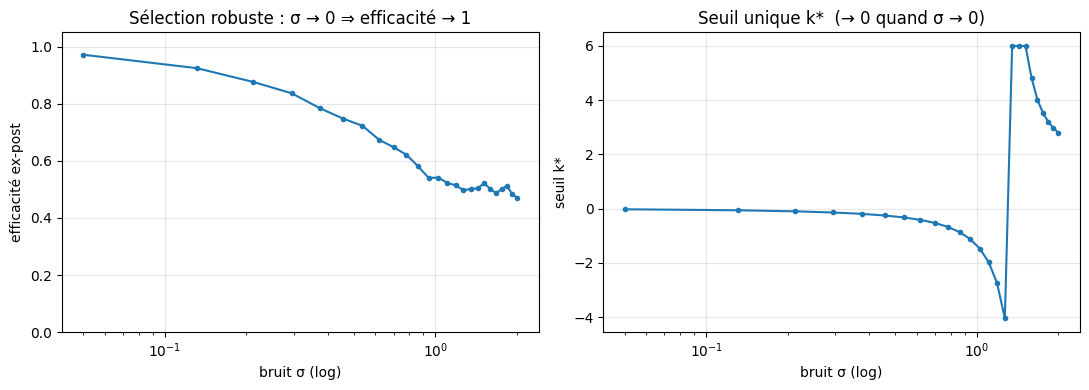

In [6]:
sigmas = np.linspace(0.05, 2.0, 25)
effs = [efficiency(s, n=4000) for s in sigmas]
ks   = [solve_cutoff(s) for s in sigmas]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sigmas, effs, marker='o', ms=3)
ax[0].set_xscale('log'); ax[0].set_ylim(0, 1.05)
ax[0].set_xlabel('bruit σ (log)'); ax[0].set_ylabel('efficacité ex-post')
ax[0].set_title('Sélection robuste : σ → 0 ⇒ efficacité → 1')
ax[0].grid(alpha=0.3)
ax[1].plot(sigmas, ks, marker='o', ms=3)
ax[1].set_xscale('log')
ax[1].set_xlabel('bruit σ (log)'); ax[1].set_ylabel('seuil k*')
ax[1].set_title('Seuil unique k*  (→ 0 quand σ → 0)')
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

***
### Exercice 1 — la multiplicité du jeu complet

Calculez la probabilité de l'action H (ligne 0) à l'équilibre mixte d'un jeu de coordination générique `[[a, b], [c, d]]`.

In [7]:
def mixed_eq_prob(a, b, c, d):
    """Probabilité de l'action H (ligne 0) à l'équilibre mixte du jeu [[a, b], [c, d]].

    Indice : l'équilibre mixte indifférise l'adversaire — sa probabilité de ligne 0
    annule l'écart de gain entre les colonnes.
    """
    # TODO etudiant
    return None
# (le cas du carnet : a=2, b=0, c=0, d=1  ->  1/3)

### Exercice 2 — le seuil unique

Complétez la fonction qui, pour un `σ` donné, calcule l'indifférence d'un joueur observant `s` face au seuil `k` (section 3).

In [8]:
def cutoff_indifference(s, k, sigma):
    """Gain(H|s) - Gain(L|s) — s'annule à s = k = k*."""
    # TODO etudiant : exprimer p(s) = P(θ>0|s)  et  q(s) = P(autre joue H | s)
    return None

### Exercice 3 — lire la sélection

En faisant varier `σ`, à partir de quelle valeur l'efficacité ex-post dépasse-t-elle **95 %** ? Qu'est-ce que cela dit sur le lien entre **précision de l'information** et **sélection de l'équilibre** ?

In [9]:
# TODO etudiant : faire varier σ et trouver le seuil d'efficacité 95 %
result = None  # TODO etudiant
print("Exercice 3 à compléter")

Exercice 3 à compléter


## En résumé

- Le jeu de coordination complet porte **trois** équilibres (deux purs, un mixte) : la multiplicité.
- Le **jeu global** (signal bruité d'un fondamental commun) ne laisse qu'**un** équilibre, à probabilité **interne** : le bruit **détruit la multiplicité**.
- Quand le signal devient **précis** (`σ → 0`), cet équilibre unique **coïncide avec l'action efficace** : la sélection est **robuste**.

**Leçons** : (1) l'information *imparfaite mais partagée* est un **résolvant** de la coordination, pas un obstacle ; (2) l'unicité de l'équilibre est une propriété du **bruit**, pas du jeu sous-jacent.

*Poursuivre* : [11 Jeux bayésiens](GameTheory-11-BayesianGames-Python.ipynb) · [17b Information asymétrique](GameTheory-17b-Asymmetric-Information-Python.ipynb).